In [66]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.datasets import fetch_california_housing

import warnings
warnings.filterwarnings("ignore")

In [67]:
housing = fetch_california_housing()

df = pd.DataFrame(housing.data, columns = housing.feature_names)
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [68]:
df["PRICE"] = housing.target
print(df.shape)
df.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,PRICE
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


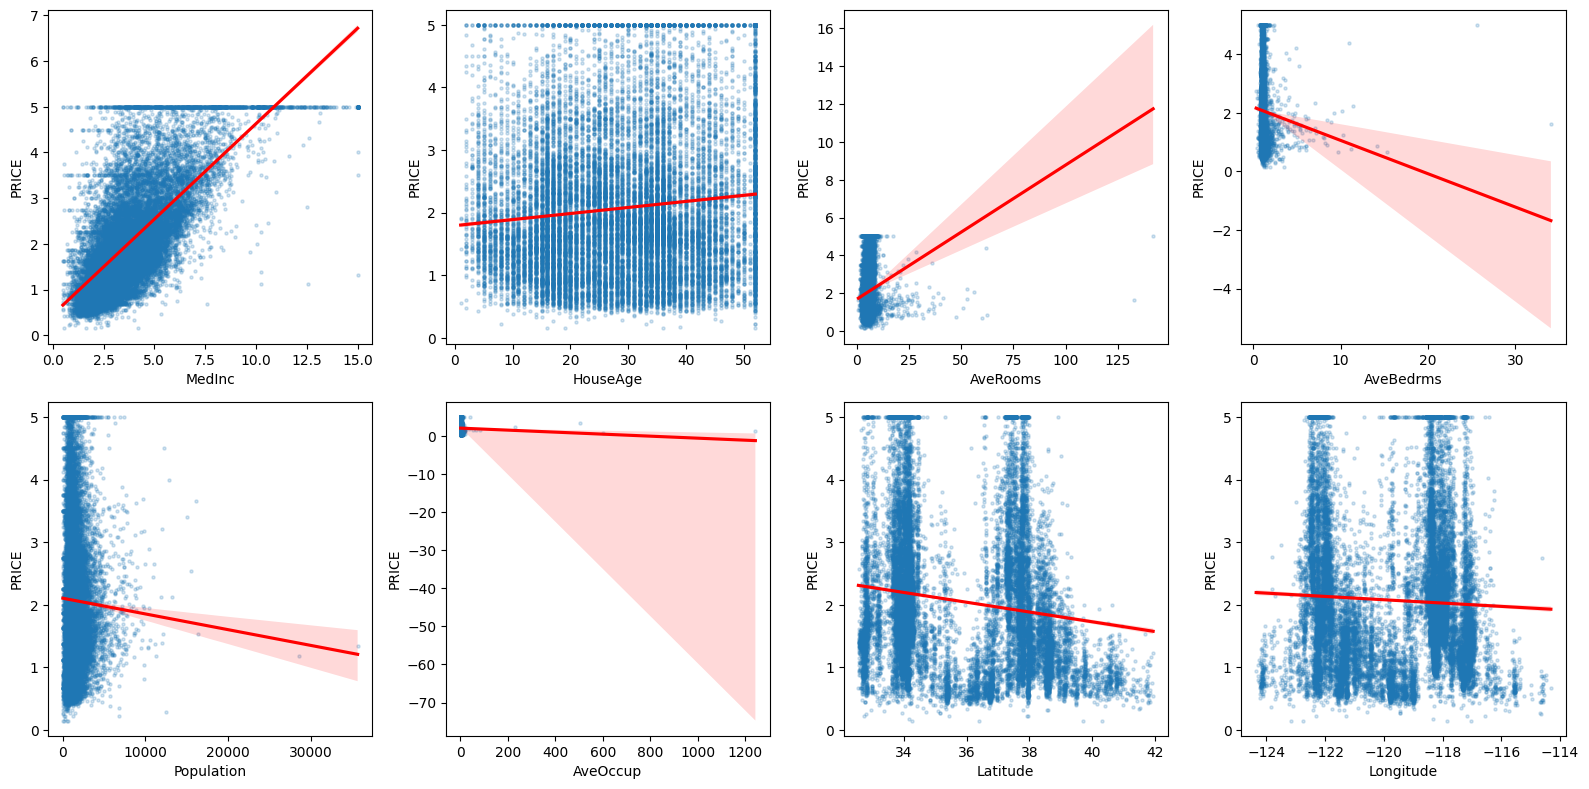

In [69]:
fig, axs = plt.subplots(figsize = (16, 8), ncols = 4, nrows = 2)
lm_features = ["MedInc", "HouseAge", "AveRooms", "AveBedrms",
               "Population", "AveOccup", "Latitude", "Longitude"]

for i, feature in enumerate(lm_features):
    row = int(i / 4)
    col = i % 4
    sns.regplot(x = feature, y = "PRICE", data = df,
                ax = axs[row][col],
                scatter_kws = {"s": 5, "alpha": 0.2},
                line_kws = {"color": "red"} )
plt.tight_layout()
plt.show()

In [70]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

y_target = df["PRICE"]
X_data = df.drop(["PRICE"], axis = 1, inplace = False)

X_train, X_test, y_train, y_test = train_test_split(X_data, y_target,
                                    test_size= 0.3, random_state = 42)

lr = LinearRegression()
lr.fit(X_train, y_train)
pred = lr.predict(X_test)
print(pred)
mse = mean_squared_error(y_test, pred)
rmse = np.sqrt(mse)
print(mse)
print(rmse)

# Variance Score
print(r2_score(y_test, pred))

[0.72604907 1.76743383 2.71092161 ... 2.07465531 1.57371395 1.82744133]
0.5305677824766749
0.728400839151545
0.5957702326061667


In [71]:
# y = a*x + b
# lr.intercept_ = b
print(lr.intercept_)
# lr.coef_ = a : 회귀계수
print(np.round(lr.coef_, 3))

-37.05624133152507
[ 0.446  0.01  -0.122  0.779 -0.    -0.003 -0.419 -0.434]


In [72]:
coeff = pd.Series(data = np.round(lr.coef_, 3), index = X_data.columns)

coeff.sort_values(ascending = False)

AveBedrms     0.779
MedInc        0.446
HouseAge      0.010
Population   -0.000
AveOccup     -0.003
AveRooms     -0.122
Latitude     -0.419
Longitude    -0.434
dtype: float64

In [73]:
from sklearn.model_selection import cross_val_score

neg_mse_scores = cross_val_score(lr, X_data, y_target,
                                 scoring = "neg_mean_squared_error",
                                 cv = 5)
rmse_scores = np.sqrt(-1 * neg_mse_scores)
avg_rmse = np.mean(rmse_scores)

print(np.round(neg_mse_scores, 2))
print(np.round(rmse_scores, 2))
print(np.round(avg_rmse, 3))

[-0.48 -0.62 -0.65 -0.54 -0.49]
[0.7  0.79 0.8  0.74 0.7 ]
0.746


In [74]:
from sklearn.preprocessing import PolynomialFeatures
import numpy as np
X = np.arange(4).reshape(2, 2)
print("일차 단항식 계수 features: ", X)

poly = PolynomialFeatures(degree = 2)
poly.fit(X)
poly_ftr = poly.transform(X)
print("변환된 2차 다항식 계수 feature: ", poly_ftr)

일차 단항식 계수 features:  [[0 1]
 [2 3]]
변환된 2차 다항식 계수 feature:  [[1. 0. 1. 0. 0. 1.]
 [1. 2. 3. 4. 6. 9.]]


In [75]:
def polynomial_func(X):
    y = 1 + 2 * X[:, 0] + 3 * X[:, 0] ** 2 + 4 * X[:, 1] ** 3
    print(X[:, 0])
    print(X[:, 1])
    return y

X = np.arange(0, 4).reshape(2, 2)

print("일차 단항식 계수 feature: ", X)
y = polynomial_func(X)
print("삼차 다항식 결정값: ", y)

일차 단항식 계수 feature:  [[0 1]
 [2 3]]
[0 2]
[1 3]
삼차 다항식 결정값:  [  5 125]


In [76]:
poly_ftr = PolynomialFeatures(degree = 3).fit_transform(X)
print("3차 다항식 계수 feature: ", poly_ftr)

3차 다항식 계수 feature:  [[ 1.  0.  1.  0.  0.  1.  0.  0.  0.  1.]
 [ 1.  2.  3.  4.  6.  9.  8. 12. 18. 27.]]


In [77]:
model = LinearRegression()
model.fit(poly_ftr, y)
print("다항식의 회귀 계수: ", np.round(model.coef_, 2))
print("다항식의 회귀 shape: ", model.coef_.shape)

다항식의 회귀 계수:  [0.   0.18 0.18 0.36 0.54 0.72 0.72 1.08 1.62 2.34]
다항식의 회귀 shape:  (10,)


In [78]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
import numpy as np

def polynomial_func(X):
    y = 1 + 2 * X[:, 0] + 3 * X[:, 0] ** 2 + 4 * X[:, 1] ** 3
    return y

model = Pipeline([("poly", PolynomialFeatures(degree = 3)),
                  ("linear", LinearRegression())])
X = np.arange(4).reshape(2, 2)
y = polynomial_func(X)

model = model.fit(X, y)
print("다항식의 회귀 계수: ", np.round(model.named_steps["linear"].coef_, 2))

다항식의 회귀 계수:  [0.   0.18 0.18 0.36 0.54 0.72 0.72 1.08 1.62 2.34]


In [79]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

def true_fun(X):
    return np.cos(1.5 * np.pi * X)
np.random.seed(0)
n_samples = 30
X = np.sort(np.random.rand(n_samples))

y = true_fun(X) + np.random.randn(n_samples) * 0.1

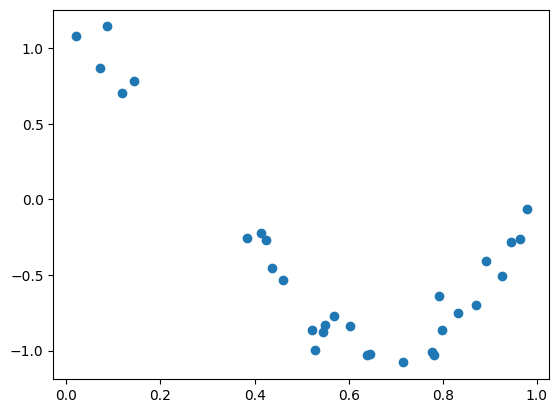

In [80]:
plt.scatter(X, y)

1 [-1.61]
1 0.40772896250986845
4 [  0.47 -17.79  23.59  -7.26]
4 0.04320874987231825
15 [-2.98293000e+03  1.03899500e+05 -1.87416382e+06  2.03716564e+07
 -1.44873571e+08  7.09316967e+08 -2.47066414e+09  6.24562771e+09
 -1.15676855e+10  1.56895436e+10 -1.54006546e+10  1.06457645e+10
 -4.91379382e+09  1.35920182e+09 -1.70381489e+08]
15 182663732.5630359


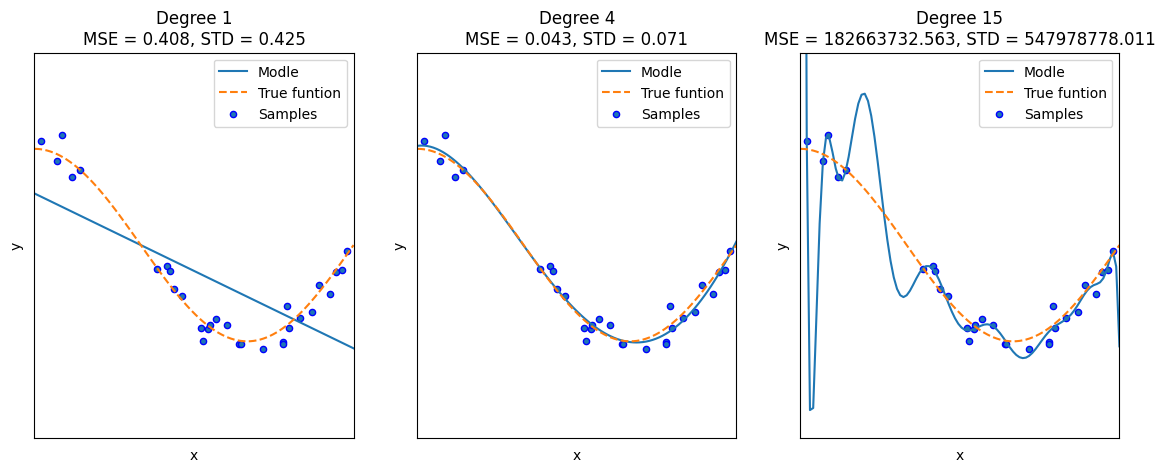

In [81]:
plt.figure(figsize = (14, 5))
degrees = [1, 4, 15]

for i in range(len(degrees)):
    ax = plt.subplot(1, len(degrees), i + 1)
    plt.setp(ax, xticks = (), yticks = ())

    polynomial_features = PolynomialFeatures(degree = degrees[i],
                                             include_bias = False)
    linear_regression = LinearRegression()
    pipeline = Pipeline([("polynomial_features", polynomial_features),
                         ("linear_regression", linear_regression)])
    pipeline.fit(X.reshape(-1, 1), y)

    scores = cross_val_score(pipeline, X.reshape(-1, 1), y,
                             scoring = "neg_mean_squared_error", cv = 10)
    coefficients = pipeline.named_steps["linear_regression"].coef_
    print(degrees[i], np.round(coefficients, 2))
    print(degrees[i], -1 * np.mean(scores))

    X_test = np.linspace(0, 1, 100)
    plt.plot(X_test, pipeline.predict(X_test[:, np.newaxis]),
             label = "Modle")
    plt.plot(X_test, true_fun(X_test), "--", label = "True funtion")
    plt.scatter(X, y, edgecolor = "b", s= 20, label = "Samples")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.xlim((0, 1))
    plt.ylim((-2, 2))
    plt.legend(loc = "best")
    plt.title(
    f"Degree {degrees[i]}\n"
    f"MSE = {-scores.mean():.3f}, STD = {scores.std():.3f}")

plt.show()

In [82]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing()
df = pd.DataFrame(housing.data, columns = housing.feature_names)

df["PRICE"] = housing.target

y_target = df["PRICE"]
X_data = df.drop(["PRICE"], axis = 1, inplace = False)

ridge = Ridge(alpha = 10)
neg_mse_scores = cross_val_score(ridge, X_data, y_target,
                    scoring = "neg_mean_squared_error", cv = 5)
rmse_scores = np.sqrt(-1 * neg_mse_scores)
avg_rmse = np.mean(rmse_scores)

print(np.round(neg_mse_scores, 3))
print(np.round(rmse_scores, 3))
print(np.round(avg_rmse, 3))

[-0.484 -0.623 -0.646 -0.544 -0.494]
[0.695 0.789 0.804 0.737 0.703]
0.746


In [83]:
alphas = [0, 0.1, 1, 10, 100]

for alpha in alphas:
    ridge = Ridge(alpha = alpha)
    neg_mse_scores = cross_val_score(ridge, X_data, y_target,
        scoring = "neg_mean_squared_error", cv = 5)
    avg_rmse = np.mean(np.sqrt(-1 * neg_mse_scores))
    print(alpha, avg_rmse)

0 0.7459068363518117
0.1 0.745905897581524
1 0.7458975215245668
10 0.7458207292972586
100 0.7455621549159905


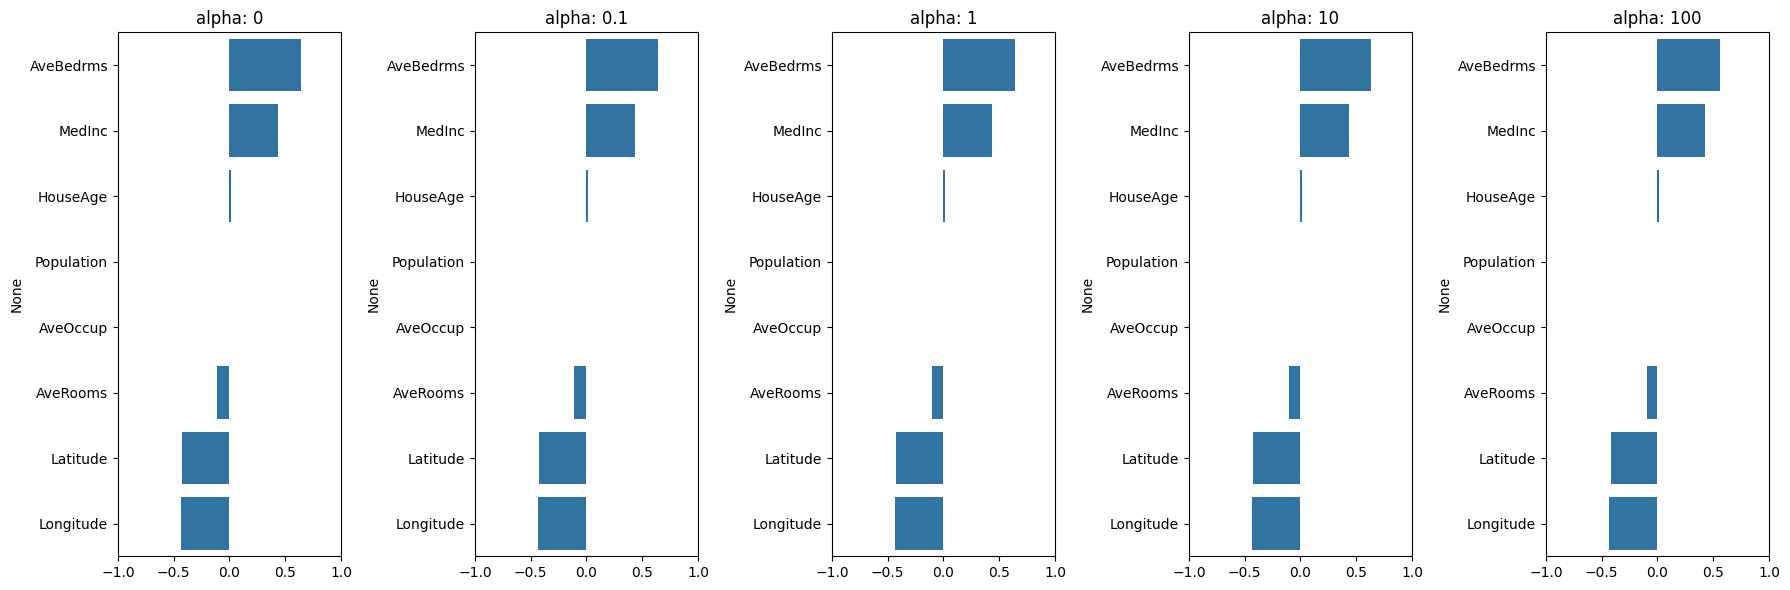

In [84]:
fig, axs = plt.subplots(figsize = (18, 6), nrows = 1, ncols = 5)
coeff_df = pd.DataFrame()

for pos, alpha in enumerate(alphas):
    ridge = Ridge(alpha = alpha)
    ridge.fit(X_data, y_target)
    coeff = pd.Series(data = ridge.coef_, index = X_data.columns)
    colname = "alpha: " + str(alpha)
    coeff_df[colname] = coeff
    coeff = coeff.sort_values(ascending = False)
    axs[pos].set_title(colname)
    axs[pos].set_xlim(-1, 1)
    sns.barplot(x = coeff.values, y = coeff.index, ax = axs[pos])

plt.tight_layout()
plt.show()

In [88]:
ridge_alphas = [0, 0.1, 1, 10, 100]
sort_column = "alpha: " + str(ridge_alphas[0])
coeff_df.sort_values(by = sort_column, ascending = False)

,alpha: 0,alpha: 0.1,alpha: 1,alpha: 10,alpha: 100
AveBedrms,0.645066,0.644965,0.644062,0.635174,0.558249
MedInc,0.436693,0.436683,0.436594,0.435719,0.428210
HouseAge,0.009436,0.009436,0.009437,0.009452,0.009592
Population,-0.000004,-0.000004,-0.000004,-0.000004,-0.000003
AveOccup,-0.003787,-0.003787,-0.003786,-0.003785,-0.003773
AveRooms,-0.107322,-0.107303,-0.107133,-0.105456,-0.091012
Latitude,-0.421314,-0.421313,-0.421299,-0.421156,-0.419061
Longitude,-0.434514,-0.434511,-0.434485,-0.434217,-0.430993


In [89]:
from sklearn.linear_model import Lasso, ElasticNet

def get_linear_reg_eval(model_name, params = None, X_data_n=None, y_target_n=None, verbose=True, return_coeff=True):
    coeff_df = pd.DataFrame()
    if verbose : print('######', model_name, '######')
    for param in params:
        if model_name == 'Ridge': model = Ridge(alpha=param)
        elif model_name == 'Lasso': model = Lasso(alpha=param)
        elif model_name == 'ElasticNet': model = ElasticNet(alpha=param, l1_ratio=0.7)
        neg_mse_scores = cross_val_score(model, X_data_n, y_target_n, scoring='neg_mean_squared_error', cv=5)
        avg_rmse = np.mean(np.sqrt(-1 * neg_mse_scores))
        print(param, avg_rmse)

        model.fit(X_data_n, y_target_n)
        if return_coeff:
            coeff = pd.Series(data=model.coef_, index=X_data_n.columns)
            colname = 'alpha:' + str(param)
            coeff_df[colname] = coeff
    return coeff_df

In [91]:
lasso_alpha = [0.07, 0.1, 0.5, 1, 3]
coeff_lasso_df = get_linear_reg_eval("Lasso",
                params = lasso_alpha, X_data_n = X_data,
                y_target_n = y_target)

###### Lasso ######
0.07 0.7843330816065586
0.1 0.8126415820543169
0.5 0.8726693609660867
1 0.9995899873740026
3 1.1710496863773499


In [98]:
sort_columns = "alpha:" + str(lasso_alpha[0])
coeff_lasso_df.sort_values(by = sort_columns, ascending = False)

,alpha:0.07,alpha:0.1,alpha:0.5,alpha:1,alpha:3
MedInc,0.387057,0.390583,0.288855,0.145469,0.000000
HouseAge,0.013391,0.015082,0.012031,0.005815,0.000000
Population,0.000010,0.000018,0.000012,-0.000006,-0.000023
AveRooms,-0.000000,-0.000000,0.000000,0.000000,0.000000
AveBedrms,0.000000,0.000000,-0.000000,-0.000000,-0.000000
AveOccup,-0.003409,-0.003323,-0.000000,-0.000000,-0.000000
Longitude,-0.204689,-0.099225,-0.000000,-0.000000,-0.000000
Latitude,-0.212806,-0.114214,-0.000000,-0.000000,-0.000000


In [104]:
elastic_alphas = [0.07, 0.1, 0.5, 1, 3]
coeff_elastic_df = get_linear_reg_eval("ElasticNet",
                params = elastic_alphas, X_data_n = X_data,
                y_target_n = y_target)

###### ElasticNet ######
0.07 0.7726785226676597
0.1 0.7884180265079879
0.5 0.8547105083610003
1 0.9306776387948424
3 1.1710447342550145


In [105]:
sort_columns = "alpha:" + str(elastic_alphas[0])
coeff_elastic_df.sort_values(by = sort_columns, ascending = False)

,alpha:0.07,alpha:0.1,alpha:0.5,alpha:1,alpha:3
MedInc,0.384500,0.385980,0.318532,0.213455,0.000000
HouseAge,0.012534,0.013697,0.013662,0.009156,0.000000
Population,0.000007,0.000012,0.000018,0.000003,-0.000023
AveRooms,0.000000,-0.000000,0.000000,0.000000,0.000000
AveBedrms,0.000000,0.000000,-0.000000,-0.000000,-0.000000
AveOccup,-0.003502,-0.003437,-0.000837,-0.000000,-0.000000
Longitude,-0.259559,-0.185737,-0.000000,-0.000000,-0.000000
Latitude,-0.264115,-0.195109,-0.000000,-0.000000,-0.000000
